In [1]:
import pandas as pd



In [2]:
ads=pd.read_csv("ad_spend.csv")
signups=pd.read_csv("signups.csv")

In [3]:
print(ads.shape , signups.shape)

(1046, 6) (18840, 7)


In [4]:
ads.head()


,date,channel,campaign,impressions,clicks,spend
0,2025-01-01,Paid Search,brand_search,1357,73,55.50
1,2025-01-01,Paid Search,generic_search,4767,112,186.15
2,2025-01-01,Paid Social,prospecting_video,37197,447,222.72
3,2025-01-01,Paid Social,retargeting,5456,85,70.38
4,2025-01-01,Display,display_network,63070,68,148.40


In [5]:
signups.head()

,user_id,signup_date,channel,campaign,subscription_start_date,plan,revenue_first_90_days
0,500001,2025-01-01,paid_social,prospecting_video,NaN,NaN,0.0
1,500002,2025-01-01,organic,NaN,NaN,NaN,0.0
2,500003,2025-01-01,affiliate,finance_blogs,NaN,NaN,0.0
3,500004,2025-01-01,paid_social,prospecting_video,NaN,NaN,0.0
4,500005,2025-01-01,referral,NaN,NaN,NaN,0.0


In [6]:
ads.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1046 entries, 0 to 1045
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         1046 non-null   object 
 1   channel      1046 non-null   object 
 2   campaign     1046 non-null   object 
 3   impressions  1046 non-null   int64  
 4   clicks       1046 non-null   int64  
 5   spend        1046 non-null   float64
dtypes: float64(1), int64(2), object(3)
memory usage: 49.2+ KB


In [7]:
signups.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18840 entries, 0 to 18839
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   user_id                  18840 non-null  int64  
 1   signup_date              18840 non-null  object 
 2   channel                  18840 non-null  object 
 3   campaign                 14266 non-null  object 
 4   subscription_start_date  2255 non-null   object 
 5   plan                     2255 non-null   object 
 6   revenue_first_90_days    18840 non-null  float64
dtypes: float64(1), int64(1), object(5)
memory usage: 1.0+ MB


In [8]:
print(ads.duplicated().sum())
print(signups.duplicated().sum())
print(ads["channel"].unique())
print(signups["channel"].unique())
print(signups["campaign"].isna().sum())     # channels with no champaign...empty row hence will give total (organic+referral)  signups 



7
0
['Paid Search' 'Paid Social' 'Display' 'Affiliate']
['paid_social' 'organic' 'affiliate' 'referral' 'paid_search' 'display']
4574


##### Rows in each  ads =1,046
##### Rows in each  signups =18,840
##### Number of duplicate rows in ads=7
##### Number of duplicate rows in signups=0
##### Channel names in ad_spend : Paid Search, Paid Social, Display, Affiliate

##### Channel names in signup: paid_social, organic affiliate ,referral ,paid_search display
##### Number of signups with no campaig- 4574 n

In [9]:
ads.drop_duplicates()

,date,channel,campaign,impressions,clicks,spend
0,2025-01-01,Paid Search,brand_search,1357,73,55.50
1,2025-01-01,Paid Search,generic_search,4767,112,186.15
2,2025-01-01,Paid Social,prospecting_video,37197,447,222.72
3,2025-01-01,Paid Social,retargeting,5456,85,70.38
4,2025-01-01,Display,display_network,63070,68,148.40
...,...,...,...,...,...,...
1041,2025-06-30,Paid Search,brand_search,1593,78,59.03
1042,2025-06-30,Paid Search,generic_search,5651,135,239.81
1043,2025-06-30,Paid Social,prospecting_video,36129,403,220.05
1044,2025-06-30,Paid Social,retargeting,5123,65,66.20


In [10]:
ads["channel_key"]=ads["channel"].str.lower().str.replace(" ","_")

In [11]:
print(ads["channel_key"].unique())
print(signups[signups['campaign'].isna()]["channel"].unique())


['paid_search' 'paid_social' 'display' 'affiliate']
['organic' 'referral']


In [12]:
print(set(ads["channel_key"]) - set(signups["channel"]))
print(set(signups["channel"]) - set(ads["channel_key"]))

set()
{'organic', 'referral'}


In [13]:
paid_signups = signups[signups["campaign"].notna()]                    # keep only signups that have a campaign
ads_pairs = set(zip(ads["channel_key"], ads["campaign"]))              # (channel, campaign) pairs in spend data
sig_pairs = set(zip(paid_signups["channel"], paid_signups["campaign"]))  # same pairs in signups
print(ads_pairs - sig_pairs)                                           # in ads but not signups; a campaign with spend but no signups
print(sig_pairs - ads_pairs) 

set()
set()


In [14]:
signups_summary = paid_signups.groupby(["channel", "campaign"]).agg(   # one row per paid campaign
    signups=("user_id", "count"),                                      # every row is one signup
    subscribers=("subscription_start_date", "count"),                  # count skips empty dates, so only paying users
    revenue=("revenue_first_90_days", "sum"),                          # total money earned in their first 90 days
).reset_index().rename(columns={"channel": "channel_key"})             # rename so the join key matches ads_summary
print(signups_summary)  

   channel_key           campaign  signups  subscribers   revenue
0    affiliate      finance_blogs      864          162   6316.41
1      display    display_network      268            8    539.88
2  paid_search       brand_search     2177          465  19470.18
3  paid_search     generic_search     2008          432  16940.61
4  paid_social  prospecting_video     6484          213   8765.43
5  paid_social        retargeting     2465          418  17411.40


In [15]:
free_users = signups[signups["subscription_start_date"].isna()]   # uRevenue by free users
print(free_users["revenue_first_90_days"].describe())    

count    16585.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: revenue_first_90_days, dtype: float64


In [16]:
 # new_column_name=("source_column", "aggregation_function")


ads_summary = ads.groupby(["channel_key", "campaign"]).agg(   # one row per campaign instead of one per day
    spend=("spend", "sum"),                                   # total money spent
    impressions=("impressions", "sum"),                       # total times the ad was shown
    clicks=("clicks", "sum"),                                 # total clicks
).reset_index()                                               # turn the group labels back into normal columns
print(ads_summary)  

   channel_key           campaign     spend  impressions  clicks
0    affiliate      finance_blogs  15489.10       710919    7794
1      display    display_network  16598.54      6660323    7907
2  paid_search       brand_search  10255.73       269367   12173
3  paid_search     generic_search  36123.97       902920   22270
4  paid_social  prospecting_video  34269.63      5720376   68774
5  paid_social        retargeting  13069.49      1092376   17373


In [17]:

combined = ads_summary.merge(signups_summary, on=["channel_key", "campaign"], how="left")   # cost and results side by side
print(len(ads_summary), len(combined))                                                      # row count should stay the same
print(combined["signups"].sum(), len(paid_signups))   

6 6
14266 14266


In [18]:
combined["ctr"] = combined["clicks"] / combined["impressions"]                 # share of views that became clicks
combined["cpc"] = combined["spend"] / combined["clicks"]                       # cost of one click
combined["cost_per_signup"] = combined["spend"] / combined["signups"]          # cost of one free account
combined["cost_per_subscriber"] = combined["spend"] / combined["subscribers"]  # cost of one paying customer
combined["roas"] = combined["revenue"] / combined["spend"]                     # revenue earned per $1 spent
print(combined.round(2)) 

   channel_key           campaign     spend  impressions  clicks  signups  \
0    affiliate      finance_blogs  15489.10       710919    7794      864   
1      display    display_network  16598.54      6660323    7907      268   
2  paid_search       brand_search  10255.73       269367   12173     2177   
3  paid_search     generic_search  36123.97       902920   22270     2008   
4  paid_social  prospecting_video  34269.63      5720376   68774     6484   
5  paid_social        retargeting  13069.49      1092376   17373     2465   

   subscribers   revenue   ctr   cpc  cost_per_signup  cost_per_subscriber  \
0          162   6316.41  0.01  1.99            17.93                95.61   
1            8    539.88  0.00  2.10            61.93              2074.82   
2          465  19470.18  0.05  0.84             4.71                22.06   
3          432  16940.61  0.02  1.62            17.99                83.62   
4          213   8765.43  0.01  0.50             5.29               16

In [19]:
rate = 96   # 1 dollar = 96 rupees (change it to today's rate)

In [20]:
combined["spend_inr"] = combined["spend"] * rate        # spend in rupees
combined["revenue_inr"] = combined["revenue"] * rate    # revenue in rupees
print(combined[["campaign", "spend", "spend_inr"]])     # check: dollars next to rupees

            campaign     spend   spend_inr
0      finance_blogs  15489.10  1486953.60
1    display_network  16598.54  1593459.84
2       brand_search  10255.73   984550.08
3     generic_search  36123.97  3467901.12
4  prospecting_video  34269.63  3289884.48
5        retargeting  13069.49  1254671.04


In [21]:
combined.to_csv("campaign_metrics.csv", index=False)                                      # save the table for your repo; index=False skips the row numbers
print(combined.sort_values("cost_per_signup")[["campaign", "cost_per_signup"]])           # best to worst by cost per signup
print(combined.sort_values("cost_per_subscriber")[["campaign", "cost_per_subscriber"]])   # best to worst by cost per paying customer

            campaign  cost_per_signup
2       brand_search         4.710946
4  prospecting_video         5.285261
5        retargeting         5.302024
0      finance_blogs        17.927199
3     generic_search        17.990025
1    display_network        61.934851
            campaign  cost_per_subscriber
2       brand_search            22.055333
5        retargeting            31.266722
3     generic_search            83.620301
0      finance_blogs            95.611728
4  prospecting_video           160.890282
1    display_network          2074.817500


In [22]:
channel_conv = signups.groupby("channel").agg(                    # one row per channel, including organic and referral
    signups=("user_id", "count"),                                 # total signups in the channel
    subscribers=("subscription_start_date", "count"),             # count skips empty dates, so only paying users
).reset_index()                                                   # turn the group labels back into a normal column
channel_conv["conversion_rate"] = channel_conv["subscribers"] / channel_conv["signups"]   # share of signups that became paying
print(channel_conv.sort_values("conversion_rate", ascending=False).round(3)) 

       channel  signups  subscribers  conversion_rate
3  paid_search     4185          897            0.214
5     referral     1063          212            0.199
0    affiliate      864          162            0.188
2      organic     3511          345            0.098
4  paid_social     8949          631            0.071
1      display      268            8            0.030


In [23]:
ads["month"] = pd.to_datetime(ads["date"]).dt.to_period("M")                                         # keep only year-month from the date
monthly_spend = ads.pivot_table(index="campaign", columns="month", values="spend", aggfunc="sum")    # rows = campaigns, columns = months, cells = spend
print(monthly_spend.round(0))  

month              2025-01  2025-02  2025-03  2025-04  2025-05  2025-06
campaign                                                               
brand_search        1753.0   1581.0   1731.0   1669.0   1769.0   1753.0
display_network     3862.0   3464.0   3859.0   3754.0   1660.0      NaN
finance_blogs       2657.0   2427.0   2550.0   2585.0   2764.0   2507.0
generic_search      6160.0   5609.0   6010.0   6029.0   6332.0   5983.0
prospecting_video   5889.0   5186.0   5795.0   5613.0   6009.0   5777.0
retargeting         2268.0   2012.0   2130.0   2218.0   2244.0   2198.0


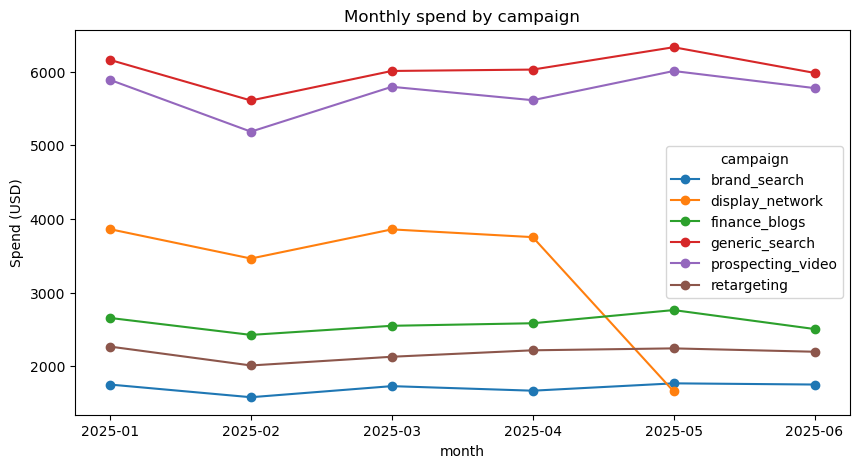

In [24]:
import matplotlib.pyplot as plt                       # the chart library

plot_data = monthly_spend.T                           # flip the table so months are rows and each campaign becomes one line
plot_data.index = plot_data.index.astype(str)         # turn months into text so the labels show correctly
plot_data.plot(figsize=(10, 5), marker="o")           # draw one line per campaign, with a dot for each month
plt.title("Monthly spend by campaign")                # chart title
plt.ylabel("Spend (USD)")                             # label for the up-down axis
plt.show()    

In [25]:
ps = paid_signups.copy()                                                                  # copy, so we don't change the original table
ps["month"] = pd.to_datetime(ps["signup_date"]).dt.to_period("M")                         # year-month of each signup
monthly_subs = ps.pivot_table(index="campaign", columns="month", values="subscription_start_date", aggfunc="count")   # paying users per campaign per month
print((monthly_spend / monthly_subs).round(0)) 

month              2025-01  2025-02  2025-03  2025-04  2025-05  2025-06
campaign                                                               
brand_search          24.0     20.0     23.0     22.0     20.0     23.0
display_network     1287.0   3464.0      inf    939.0      inf      NaN
finance_blogs         81.0    106.0     94.0     81.0    115.0    109.0
generic_search        81.0     76.0     81.0     81.0     99.0     85.0
prospecting_video    227.0    153.0    157.0    148.0    154.0    148.0
retargeting           32.0     34.0     30.0     31.0     29.0     32.0
